<a href="https://colab.research.google.com/github/fathiobiedmohammedalamin-byte/VISIONAI/blob/main/Bankak_Reviews.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ضgoogle-play-scraper pandas

In [ ]:


from google_play_scraper import Sort, reviews
import pandas as pd
import time

app_id = "com.mode.bok.ui"

all_reviews = []
token = None

while len(all_reviews) < 2000:
    batch, token = reviews(
        app_id,
        lang="ar",
        country="sd",
        sort=Sort.NEWEST,
        count=200,
        continuation_token=token
    )

    if not batch:
        break

    all_reviews.extend(batch)

    print("تم جمع:", len(all_reviews))

    if token is None:
        break

    time.sleep(1)

df = pd.DataFrame(all_reviews)

df = df.drop_duplicates(subset=["reviewId"])

df = df[[
    "reviewId",
    "content",
    "score",
    "at",
    "thumbsUpCount",
    "reviewCreatedVersion"
]]

df.columns = [
    "review_id",
    "review",
    "rating",
    "date",
    "likes",
    "app_version"
]

df.to_csv(
    "bankak_2000_reviews.csv",
    index=False,
    encoding="utf-8-sig"
)

print("إجمالي التعليقات:", len(df))

تم جمع: 200
تم جمع: 400
تم جمع: 600
تم جمع: 800
تم جمع: 1000
تم جمع: 1200
تم جمع: 1400
تم جمع: 1600
تم جمع: 1800
تم جمع: 2000
إجمالي التعليقات: 2000


In [ ]:

from google.colab import files
files.download("bankak_2000_reviews.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Device: GPU

STEP 1: Collecting reviews...
Collected: 200
Collected: 400
Collected: 600
Collected: 800
Collected: 1000
Collected: 1200
Collected: 1400
Collected: 1600
Collected: 1800
Collected: 2000
Final dataset: 2000

STEP 2: Processing Arabic text...

STEP 3: Loading Arabic sentiment model...


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

... (32 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Emotions: 8 / 1988
Emotions: 16 / 1988
Emotions: 24 / 1988
Emotions: 32 / 1988
Emotions: 40 / 1988
Emotions: 48 / 1988
Emotions: 56 / 1988
Emotions: 64 / 1988
Emotions: 72 / 1988
Emotions: 80 / 1988
Emotions: 88 / 1988
Emotions: 96 / 1988
Emotions: 104 / 1988
Emotions: 112 / 1988
Emotions: 120 / 1988
Emotions: 128 / 1988
Emotions: 136 / 1988
Emotions: 144 / 1988
Emotions: 152 / 1988
Emotions: 160 / 1988
Emotions: 168 / 1988
Emotions: 176 / 1988
Emotions: 184 / 1988
Emotions: 192 / 1988
Emotions: 200 / 1988
Emotions: 208 / 1988
Emotions: 216 / 1988
Emotions: 224 / 1988
Emotions: 232 / 1988
Emotions: 240 / 1988
Emotions: 248 / 1988
Emotions: 256 / 1988
Emotions: 264 / 1988
Emotions: 272 / 1988
Emotions: 280 / 1988
Emotions: 288 / 1988
Emotions: 296 / 1988
Emotions: 304 / 1988
Emotions: 312 / 1988
Emotions: 320 / 1988
Emotions: 328 / 1988
Emotions: 336 / 1988
Emotions: 344 / 1988
Emotions: 352 / 1988
Emotions: 360 / 1988
Emotions: 368 / 1988
Emotions: 376 / 1988
Emotions: 384 / 1988
Emoti

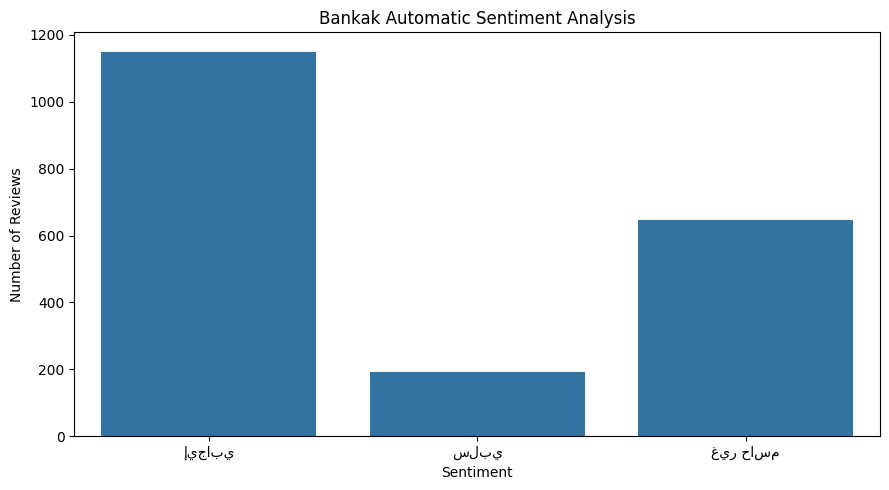

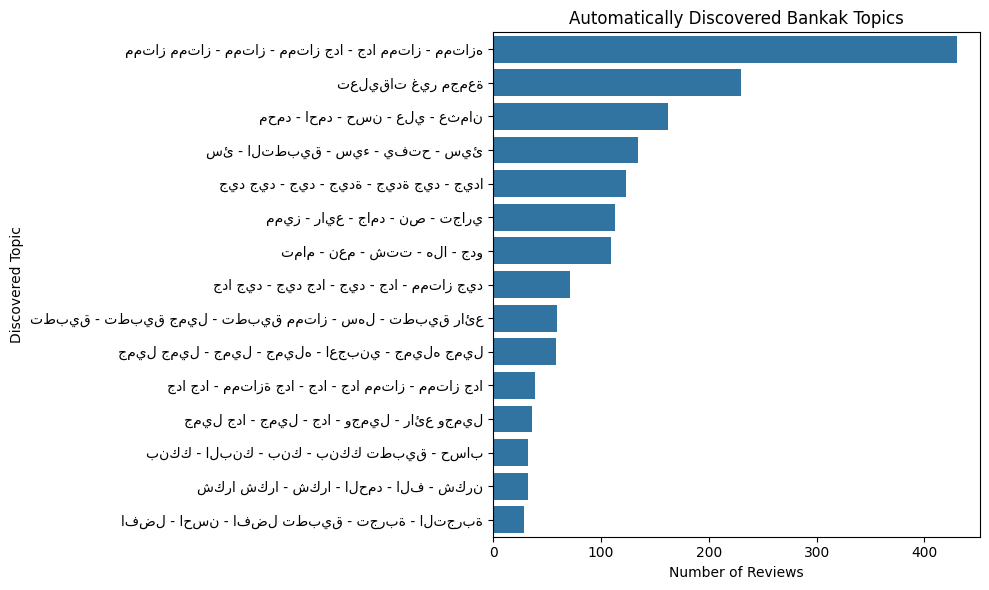

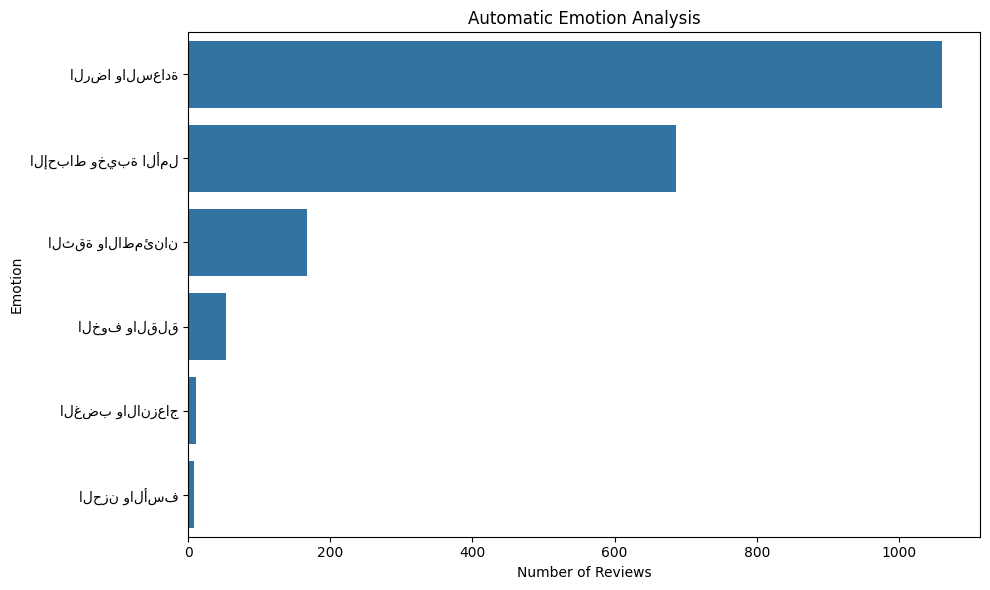

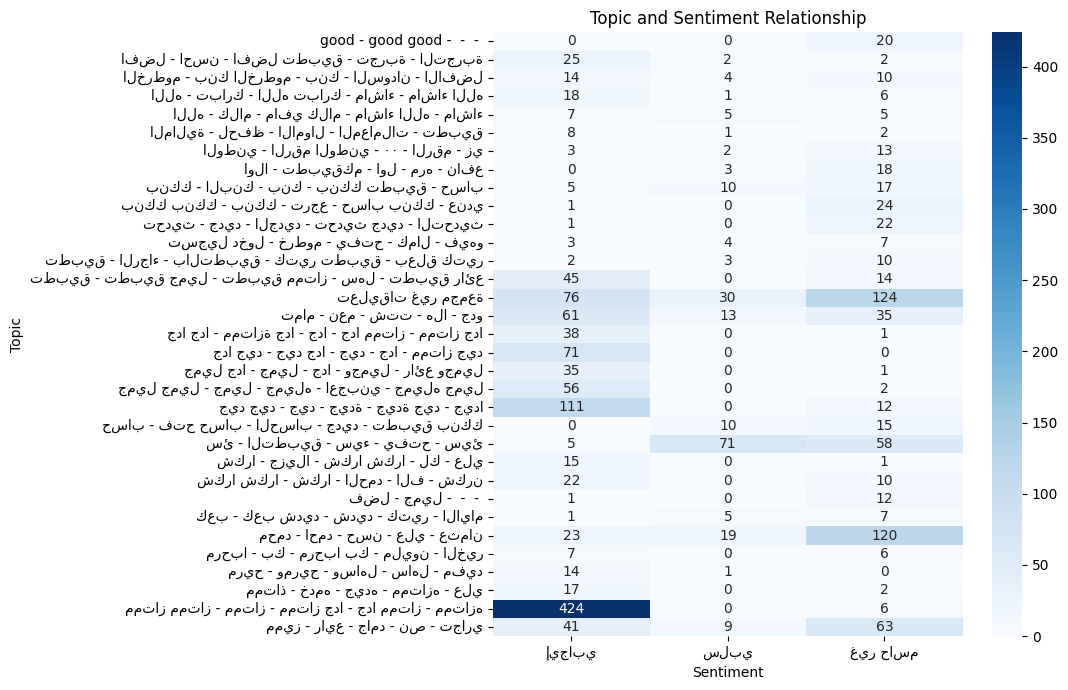


STEP 8: Exporting research files...

BANKAK DEEP NLP ANALYSIS COMPLETED
Total reviews: 1988
Average rating: 4.45
Sentiment classes:
sentiment
إيجابي      1150
غير حاسم     645
سلبي         193
Name: count, dtype: int64
Discovered topics: 32

Generated files:
1. bankak_raw_reviews.csv
2. bankak_deep_analysis.csv
3. bankak_deep_research_report.xlsx
4. 01_sentiment.png
5. 02_topics.png
6. 03_emotions.png
7. 04_topic_sentiment.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (6 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


ALL FILES READY.


In [4]:

# ================================================================
# BANKAK DEEP RESEARCH SYSTEM
# Automatic Sudanese Arabic NLP - 2000 Google Play Reviews
# Sentiment + Topic Discovery + Emotion + Opinion Analysis
# NO HUMAN LABELING / NO MANUAL TRAINING
# ================================================================

# 1. INSTALL LIBRARIES
!pip -q install google-play-scraper transformers sentencepiece \
sentence-transformers bertopic umap-learn hdbscan \
pandas numpy matplotlib seaborn openpyxl

import re
import time
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from google_play_scraper import Sort, reviews
from transformers import pipeline
from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from sklearn.feature_extraction.text import CountVectorizer

warnings.filterwarnings("ignore")

# ================================================================
# 2. CONFIGURATION
# ================================================================

APP_ID = "com.mode.bok.ui"
TARGET_REVIEWS = 2000

SENTIMENT_MODEL = (
    "CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment"
)

EMBEDDING_MODEL = (
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

EMOTION_MODEL = (
    "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
)

DEVICE = 0 if torch.cuda.is_available() else -1

# Low confidence is treated as uncertain, not proven neutral.
NEUTRAL_THRESHOLD = 0.60

print("Device:", "GPU" if DEVICE == 0 else "CPU")

# ================================================================
# 3. COLLECT GOOGLE PLAY REVIEWS
# ================================================================

print("\nSTEP 1: Collecting reviews...")

all_reviews = []
token = None

while len(all_reviews) < TARGET_REVIEWS:

    batch, token = reviews(
        APP_ID,
        lang="ar",
        country="sd",
        sort=Sort.NEWEST,
        count=200,
        continuation_token=token
    )

    if not batch:
        break

    all_reviews.extend(batch)

    all_reviews = list({
        item["reviewId"]: item
        for item in all_reviews
    }.values())

    print("Collected:", len(all_reviews))

    if token is None:
        break

    time.sleep(1)

df = pd.DataFrame(all_reviews)

if df.empty:
    raise ValueError("No reviews collected. Check internet and App ID.")

df = df.drop_duplicates(subset=["reviewId"])

df = df[[
    "reviewId",
    "content",
    "score",
    "at",
    "thumbsUpCount",
    "reviewCreatedVersion"
]].copy()

df.columns = [
    "review_id",
    "review",
    "rating",
    "date",
    "likes",
    "app_version"
]

df = df.dropna(subset=["review"])

df["review"] = df["review"].astype(str)

df = df[df["review"].str.strip() != ""].copy()

df = df.reset_index(drop=True)

print("Final dataset:", len(df))

# Save raw data
df.to_csv(
    "bankak_raw_reviews.csv",
    index=False,
    encoding="utf-8-sig"
)

# ================================================================
# 4. ARABIC TEXT PREPROCESSING
# ================================================================

print("\nSTEP 2: Processing Arabic text...")

def clean_arabic(text):

    text = str(text)

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove Arabic diacritics
    text = re.sub(r"[\u064B-\u065F\u0670ـ]", "", text)

    # Normalize Arabic letters
    text = re.sub(r"[إأآٱ]", "ا", text)
    text = re.sub(r"ى", "ي", text)

    # Remove excessive repeated characters
    text = re.sub(r"(.)\1{3,}", r"\1\1", text)

    # Normalize spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["clean_review"] = df["review"].apply(clean_arabic)

# Preserve negation, dialect words and original meaning.
df = df[df["clean_review"].str.len() > 1].copy()

df = df.reset_index(drop=True)

# ================================================================
# 5. AUTOMATIC SENTIMENT ANALYSIS
# CAMeLBERT Dialectal Arabic
# ================================================================

print("\nSTEP 3: Loading Arabic sentiment model...")

sentiment_model = pipeline(
    "text-classification",
    model=SENTIMENT_MODEL,
    device=DEVICE
)

texts = df["review"].tolist()

sentiment_results = []

for start in range(0, len(texts), 32):

    batch = texts[start:start + 32]

    predictions = sentiment_model(
        batch,
        batch_size=32,
        truncation=True,
        max_length=256
    )

    sentiment_results.extend(predictions)

    print(
        "Sentiment:",
        min(start + 32, len(texts)),
        "/",
        len(texts)
    )

df["sentiment_model_label"] = [
    p["label"] for p in sentiment_results
]

df["sentiment_confidence"] = [
    p["score"] for p in sentiment_results
]

def translate_sentiment(label, confidence):

    label = str(label).lower()

    if confidence < NEUTRAL_THRESHOLD:
        return "غير حاسم"

    if "positive" in label:
        return "إيجابي"

    if "negative" in label:
        return "سلبي"

    return "غير حاسم"

df["sentiment"] = [
    translate_sentiment(label, score)
    for label, score in zip(
        df["sentiment_model_label"],
        df["sentiment_confidence"]
    )
]

# ================================================================
# 6. AUTOMATIC TOPIC DISCOVERY - BERTOPIC
# No predefined topic categories
# ================================================================

print("\nSTEP 4: Discovering discussion topics...")

embedding_model = SentenceTransformer(
    EMBEDDING_MODEL,
    device="cuda" if DEVICE == 0 else "cpu"
)

# Arabic stop words for topic keyword extraction
arabic_stopwords = [
    "في", "من", "على", "الى", "إلى", "عن",
    "هذا", "هذه", "ذلك", "التي", "الذي",
    "هو", "هي", "كان", "كانت", "مع",
    "ما", "لا", "لم", "لن", "ان", "أن",
    "كل", "بعد", "قبل", "او", "أو",
    "انا", "أنا", "انت", "أنت", "نحن",
    "بس", "لكن", "والله", "يا", "ده", "دي"
]

vectorizer = CountVectorizer(
    ngram_range=(1, 2),
    stop_words=arabic_stopwords,
    min_df=2
)

topic_model = BERTopic(
    embedding_model=embedding_model,
    vectorizer_model=vectorizer,
    min_topic_size=10,
    nr_topics="auto",
    calculate_probabilities=False,
    verbose=True
)

topic_ids, topic_probabilities = topic_model.fit_transform(
    df["clean_review"].tolist()
)

df["topic_id"] = topic_ids

# Extract automatically generated topic keywords
topic_names = {}

for topic_id in sorted(set(topic_ids)):

    if topic_id == -1:
        topic_names[topic_id] = "تعليقات غير مجمعة"
        continue

    words = topic_model.get_topic(topic_id)

    if words:
        keywords = [word for word, score in words[:5]]
        topic_names[topic_id] = " - ".join(keywords)
    else:
        topic_names[topic_id] = "موضوع غير محدد"

df["topic_name"] = df["topic_id"].map(topic_names)

print("Discovered topics:", len(set(topic_ids)) - (1 if -1 in topic_ids else 0))

# ================================================================
# 7. AUTOMATIC EMOTION ANALYSIS - ZERO SHOT
# ================================================================

print("\nSTEP 5: Loading emotion model...")

emotion_classifier = pipeline(
    "zero-shot-classification",
    model=EMOTION_MODEL,
    device=DEVICE
)

emotion_labels = [
    "الغضب والانزعاج",
    "الإحباط وخيبة الأمل",
    "الرضا والسعادة",
    "الثقة والاطمئنان",
    "الحزن والأسف",
    "الخوف والقلق"
]

emotion_results = []

for start in range(0, len(df), 8):

    batch = df["clean_review"].iloc[start:start + 8].tolist()

    results = emotion_classifier(
        batch,
        candidate_labels=emotion_labels,
        hypothesis_template="يعبر هذا التعليق عن {}.",
        multi_label=True,
        batch_size=8
    )

    emotion_results.extend(results)

    print(
        "Emotions:",
        min(start + 8, len(df)),
        "/",
        len(df)
    )

# Main emotion and secondary emotions
main_emotions = []
secondary_emotions = []
emotion_confidences = []

for result in emotion_results:

    scores = list(zip(result["labels"], result["scores"]))

    scores = sorted(
        scores,
        key=lambda x: x[1],
        reverse=True
    )

    main_emotions.append(scores[0][0])
    emotion_confidences.append(scores[0][1])

    secondary = [
        label for label, score in scores[1:]
        if score >= 0.40
    ]

    secondary_emotions.append("؛ ".join(secondary))

df["main_emotion"] = main_emotions

df["emotion_confidence"] = emotion_confidences

df["secondary_emotions"] = secondary_emotions

# ================================================================
# 8. AUTOMATIC OPINION AND PROBLEM ANALYSIS
# ================================================================

print("\nSTEP 6: Analyzing user opinions...")

# Topic + sentiment combination
df["opinion_category"] = (
    df["topic_name"].astype(str)
    + " | "
    + df["sentiment"].astype(str)
)

# Find topics associated with negative opinions
negative_reviews = df[
    df["sentiment"] == "سلبي"
]

negative_topics = (
    negative_reviews["topic_name"]
    .value_counts()
    .rename_axis("الموضوع")
    .reset_index(name="عدد الآراء السلبية")
)

# Most common topics
topic_summary = (
    df.groupby(["topic_id", "topic_name"])
    .size()
    .reset_index(name="عدد التعليقات")
    .sort_values("عدد التعليقات", ascending=False)
)

# Sentiment by topic
topic_sentiment = pd.crosstab(
    df["topic_name"],
    df["sentiment"]
)

# Emotion distribution
emotion_summary = (
    df["main_emotion"]
    .value_counts()
    .rename_axis("الانفعال")
    .reset_index(name="العدد")
)

# ================================================================
# 9. SENTIMENT STATISTICS
# ================================================================

sentiment_summary = (
    df["sentiment"]
    .value_counts()
    .rename_axis("المشاعر")
    .reset_index(name="العدد")
)

sentiment_summary["النسبة المئوية"] = (
    sentiment_summary["العدد"] / len(df) * 100
).round(2)

rating_summary = (
    df["rating"]
    .value_counts()
    .sort_index()
    .rename_axis("التقييم")
    .reset_index(name="العدد")
)

print("\n========== RESEARCH RESULTS ==========")

print("\nSentiment:")
print(sentiment_summary)

print("\nTopics:")
print(topic_summary)

print("\nEmotions:")
print(emotion_summary)

print("\nNegative opinions:")
print(negative_topics)

print("\nAverage Google Play rating:", df["rating"].mean())

# ================================================================
# 10. VISUALIZATION
# ================================================================

print("\nSTEP 7: Creating charts...")

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="sentiment",
    order=["إيجابي", "سلبي", "غير حاسم"]
)

plt.title("Bankak Automatic Sentiment Analysis")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.savefig("01_sentiment.png", dpi=300)
plt.show()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=topic_summary.head(15),
    x="عدد التعليقات",
    y="topic_name"
)

plt.title("Automatically Discovered Bankak Topics")
plt.xlabel("Number of Reviews")
plt.ylabel("Discovered Topic")
plt.tight_layout()
plt.savefig("02_topics.png", dpi=300)
plt.show()

plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="main_emotion",
    order=df["main_emotion"].value_counts().index
)

plt.title("Automatic Emotion Analysis")
plt.xlabel("Number of Reviews")
plt.ylabel("Emotion")
plt.tight_layout()
plt.savefig("03_emotions.png", dpi=300)
plt.show()

plt.figure(figsize=(11, 7))

sns.heatmap(
    topic_sentiment,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Topic and Sentiment Relationship")
plt.xlabel("Sentiment")
plt.ylabel("Topic")
plt.tight_layout()
plt.savefig("04_topic_sentiment.png", dpi=300)
plt.show()

# ================================================================
# 11. EXPORT ALL RESEARCH DATA
# ================================================================

print("\nSTEP 8: Exporting research files...")

df.to_csv(
    "bankak_deep_analysis.csv",
    index=False,
    encoding="utf-8-sig"
)

with pd.ExcelWriter("bankak_deep_research_report.xlsx") as writer:

    df.to_excel(
        writer,
        sheet_name="All Reviews",
        index=False
    )

    sentiment_summary.to_excel(
        writer,
        sheet_name="Sentiment",
        index=False
    )

    topic_summary.to_excel(
        writer,
        sheet_name="Discovered Topics",
        index=False
    )

    topic_sentiment.to_excel(
        writer,
        sheet_name="Topic Sentiment",
    )

    emotion_summary.to_excel(
        writer,
        sheet_name="Emotions",
        index=False
    )

    negative_topics.to_excel(
        writer,
        sheet_name="Negative Opinions",
        index=False
    )

    rating_summary.to_excel(
        writer,
        sheet_name="Ratings",
        index=False
    )

# ================================================================
# 12. FINAL REPORT
# ================================================================

print("\n====================================")
print("BANKAK DEEP NLP ANALYSIS COMPLETED")
print("====================================")

print("Total reviews:", len(df))

print("Average rating:", round(df["rating"].mean(), 2))

print("Sentiment classes:")
print(df["sentiment"].value_counts())

print("Discovered topics:",
      len(set(topic_ids)) - (1 if -1 in topic_ids else 0))

print("\nGenerated files:")
print("1. bankak_raw_reviews.csv")
print("2. bankak_deep_analysis.csv")
print("3. bankak_deep_research_report.xlsx")
print("4. 01_sentiment.png")
print("5. 02_topics.png")
print("6. 03_emotions.png")
print("7. 04_topic_sentiment.png")

# ================================================================
# 13. DOWNLOAD FILES
# ================================================================

from google.colab import files

for filename in [
    "bankak_raw_reviews.csv",
    "bankak_deep_analysis.csv",
    "bankak_deep_research_report.xlsx",
    "01_sentiment.png",
    "02_topics.png",
    "03_emotions.png",
    "04_topic_sentiment.png"
]:
    if os.path.exists(filename):
        files.download(filename)

print("\nALL FILES READY.")